In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cmb = pd.read_csv("../_cmb/processed/planck_samples.csv.gz")

grid = np.load("results/h0rd_grid.npz")

omega_m = grid["Omega_m"]
h0rd_grid = grid["H0rd"]
joint_chi2 = grid["joint_chi2"]

weights = cmb["weight"].values
weights = weights / np.sum(weights)

assert joint_chi2.shape == (len(omega_m), len(h0rd_grid))

In [2]:
planck_om = cmb["Omega_m"].values
planck_h0rd = cmb["H0rd"].values

mean_om = np.average(planck_om, weights=weights)
mean_h0rd = np.average(planck_h0rd, weights=weights)

difference_om = planck_om - mean_om
difference_h0rd = planck_h0rd - mean_h0rd

var_om = np.average(difference_om**2, weights=weights)
var_h0rd = np.average(difference_h0rd**2, weights=weights)

covariance = np.average(
    difference_om * difference_h0rd,
    weights=weights,
)

rho = covariance / (var_om * var_h0rd)**0.5

pd.DataFrame({
    "Omega_m_mean": [mean_om],
    "H0rd_mean": [mean_h0rd],
    "correlation": [rho],
})

,Omega_m_mean,H0rd_mean,correlation
0,0.316551,9892.785689,-0.999113


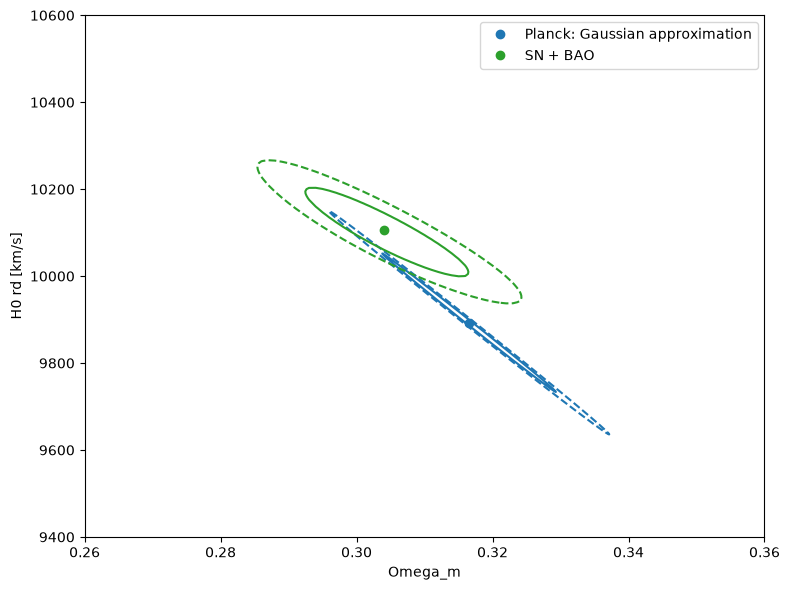

In [9]:
planck_cov = np.array([
    [var_om, covariance],
    [covariance, var_h0rd],
])

values, vectors = np.linalg.eigh(planck_cov)
assert (values > 0).all()

angle = np.linspace(0, 2 * np.pi, 1000)
circle = np.array([np.cos(angle), np.sin(angle)])
center = np.array([mean_om, mean_h0rd]).reshape(2, 1)

joint_delta = joint_chi2 - np.min(joint_chi2)

best = np.argmin(joint_chi2)
i = best // len(h0rd_grid)
j = best % len(h0rd_grid)

plt.figure(figsize=(8, 6))

for level, style in [(2.30, "-"), (5.99, "--")]:
    ellipse = center + vectors @ (
        np.sqrt(level * values).reshape(2, 1) * circle
    )

    plt.plot(
        ellipse[0],
        ellipse[1],
        linestyle=style,
        color="tab:blue",
    )

plt.contour(
    omega_m,
    h0rd_grid,
    joint_delta.T,
    levels=[2.30, 5.99],
    colors=["tab:green"],
    linestyles=["solid", "dashed"],
)

plt.plot(
    mean_om, mean_h0rd,
    "o", color="tab:blue",
    label="Planck: Gaussian approximation",
)
plt.plot(
    omega_m[i], h0rd_grid[j],
    "o", color="tab:green",
    label="SN + BAO",
)

plt.xlim(0.26, 0.36)
plt.ylim(9400, 10600)
plt.xlabel("Omega_m")
plt.ylabel("H0 rd [km/s]")
plt.legend()
plt.tight_layout()
plt.savefig("results/planck_joint_comparison.png", dpi=200)
plt.show()

In [4]:
probability = np.exp(-0.5 * joint_delta)
probability = probability / np.sum(probability)

edge_probability = (
    np.sum(probability[0, :])
    + np.sum(probability[-1, :])
    + np.sum(probability[:, 0])
    + np.sum(probability[:, -1])
)

assert edge_probability < 0.001

N_SAMPLE = 100000
np.random.seed(42)

selected = np.random.choice(
    probability.size,
    size=N_SAMPLE,
    p=probability.ravel(),
)

omega_samples = omega_m[selected // len(h0rd_grid)]
h0rd_samples = h0rd_grid[selected % len(h0rd_grid)]

In [5]:
selected_cmb = np.random.choice(
    len(cmb),
    size=N_SAMPLE,
    p=weights,
)

rd_samples = cmb["rd"].values[selected_cmb]
h0_samples = h0rd_samples / rd_samples

calibrated = pd.DataFrame({
    "Omega_m": omega_samples,
    "H0rd": h0rd_samples,
    "rd": rd_samples,
    "H0": h0_samples,
})

calibrated.to_csv(
    "results/h0_rd_calibrated_samples.csv.gz",
    index=False,
    compression="gzip",
)

pd.DataFrame({
    "model": ["flat LCDM"],
    "late_data": ["SN + BAO"],
    "prior": ["uniform Omega_m and H0rd within saved grid"],
    "calibration": ["Planck TTTEEE+lowl+lowE marginal rd posterior"],
    "samples": [N_SAMPLE],
}).to_csv("results/h0_rd_calibration_settings.csv", index=False)

In [6]:
def weighted_quantiles(values, weights):
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    probability = (
        np.cumsum(weights) - weights / 2
    ) / np.sum(weights)

    return np.interp([0.16, 0.50, 0.84], probability, values)


p_low, p_median, p_high = weighted_quantiles(
    cmb["H0"].values,
    weights,
)

h_low, h_median, h_high = np.quantile(
    h0_samples,
    [0.16, 0.50, 0.84],
)

summary = pd.DataFrame({
    "analysis": [
        "Planck",
        "SN + BAO with Planck rd calibration",
    ],
    "H0_median": [p_median, h_median],
    "lower_68": [p_low, h_low],
    "upper_68": [p_high, h_high],
    "error_minus": [p_median - p_low, h_median - h_low],
    "error_plus": [p_high - p_median, h_high - h_median],
})

summary.to_csv("results/h0_comparison.csv", index=False)

summary

,analysis,H0_median,lower_68,upper_68,error_minus,error_plus
0,Planck,67.268070,66.677250,67.873540,0.590820,0.605470
1,SN + BAO with Planck rd calibration,68.684986,68.216245,69.160357,0.468741,0.475371


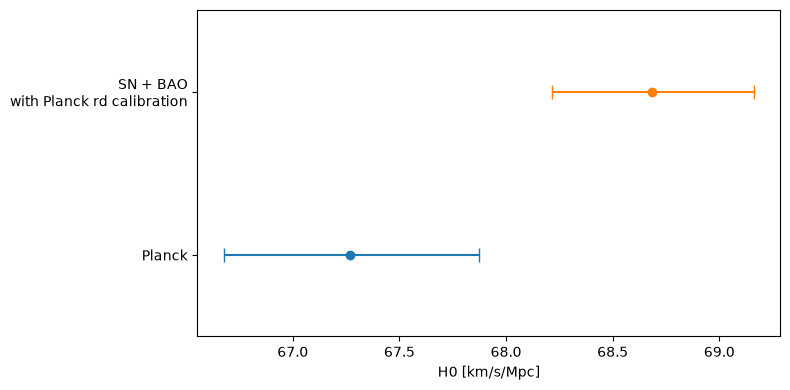

In [8]:
plt.figure(figsize=(8, 4))

for i in range(len(summary)):
    row = summary.iloc[i]

    plt.errorbar(
        row["H0_median"],
        i,
        xerr=[[row["error_minus"]], [row["error_plus"]]],
        fmt="o",
        capsize=5,
    )

plt.yticks(
    [0, 1],
    ["Planck", "SN + BAO\nwith Planck rd calibration"],
)
plt.ylim(-0.5, 1.5)
plt.xlabel("H0 [km/s/Mpc]")
plt.tight_layout()
plt.savefig("results/h0_comparison.png", dpi=200)
plt.show()